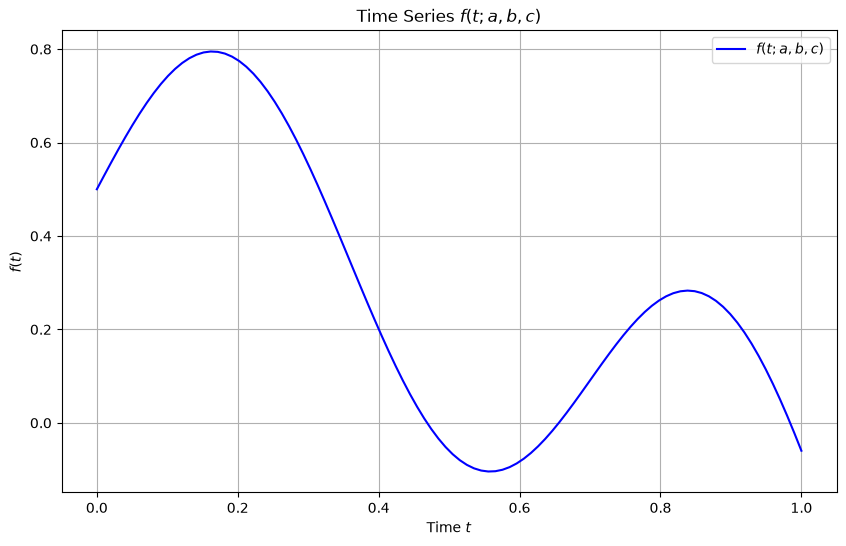

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def f(t, a, b, c):
    return np.sqrt(a) * np.exp(-b * t) * np.sin(c * t) + 0.5 * np.cos(2 * t)

# Example usage
# Define parameters
a = 0.1
b = -0.13
c = 9


# Define time range
t = np.linspace(0, 1, 100)  # time from 0 to 1 with 100 points

# Calculate f(t) for these parameters
f_values = f(t, a, b, c)

# Plot the function
plt.figure(figsize=(10, 6))
plt.plot(t, f_values, label=r'$f(t; a, b, c)$', color='blue')
plt.xlabel('Time $t$')
plt.ylabel(r'$f(t)$')
plt.title(r'Time Series $f(t; a, b, c)$')
plt.legend()
plt.grid(True)
plt.show()

In [2]:
from ipywidgets import interactive
import ipywidgets as widgets


def plot_with_parameters(a, b, c):
    # Define time range
    t = np.linspace(0, 1, 100)

    # Calculate f(t) for these parameters
    f_values = f(t, a, b, c)

    # Plot the function
    plt.figure(figsize=(10, 6))
    plt.plot(t, f_values, label=r'$f(t; a, b, c)$', color='blue')
    plt.xlabel('Time $t$')
    plt.ylabel(r'$f(t)$')
    plt.title(r'Time Series $f(t; a, b, c)$')
    plt.legend()
    plt.grid(True)
    plt.show()

# Create interactive widget
interactive_plot = interactive(
    plot_with_parameters,
    a=widgets.FloatSlider(min=0, max=1, step=0.01, value=0.1),
    b=widgets.FloatSlider(min=-0.5, max=0.5, step=0.01, value=-0.13),
    c=widgets.FloatSlider(min=5, max=10, step=0.1, value=9)
)

display(interactive_plot)

interactive(children=(FloatSlider(value=0.1, description='a', max=1.0, step=0.01), FloatSlider(value=-0.13, de…

Question 1

In [3]:
from scipy.interpolate import interp1d

# Create the cubic interpolation function
F_interp_t = interp1d(
    t,
    f_values,
    kind='cubic',
    fill_value="extrapolate"
)

# Calculate interpolated values
f_value_at_t_new = F_interp_t(t)

Question 2

In [4]:
# Create a finer time grid
t_new = np.linspace(0, 1, 1000)

# Calculate interpolated values with finer time grid
f_value_at_t_new = F_interp_t(t_new)

Question 3

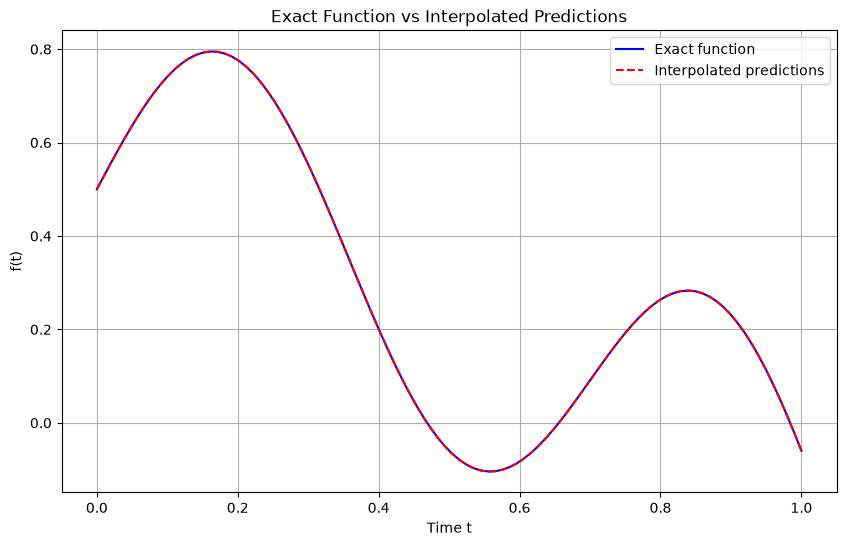

In [5]:
plt.figure(figsize=(10, 6))

plt.plot(t, f_values, label='Exact function', color='blue')

plt.plot(
    t_new,
    f_value_at_t_new,
    label='Interpolated predictions',
    color='red',
    linestyle='--'
)

plt.xlabel('Time t')
plt.ylabel('f(t)')
plt.title('Exact Function vs Interpolated Predictions')

plt.legend()
plt.grid(True)
plt.show()

**Explanation:**

In this question, we use cubic interpolation to estimate function values at 1001 equally spaced points. The interpolated predictions are plotted together with the original function to visually assess how well the cubic interpolation approximates the exact function.

Question 4

In [6]:
# Calculate the true function values on the finer grid
true_values = f(t_new, a, b, c)

In [7]:
# Calculate relative difference in percentage
r = 100 * (f_value_at_t_new - true_values) / true_values

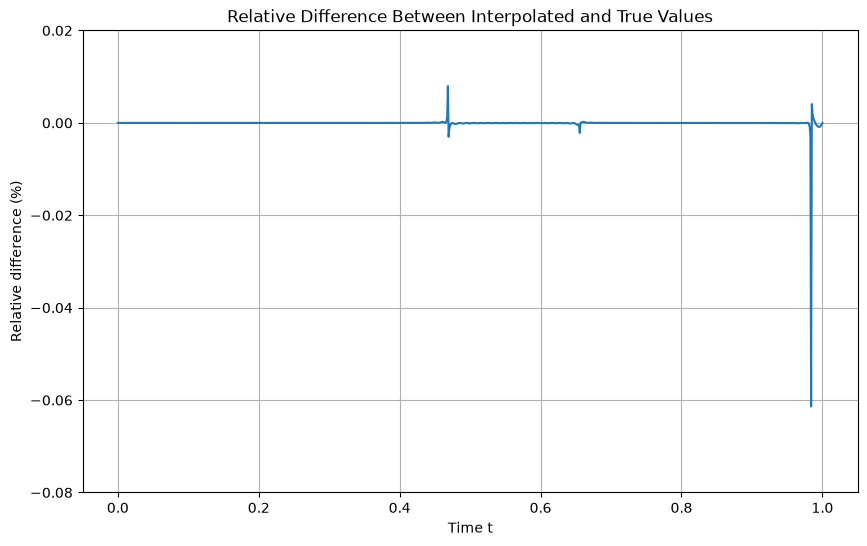

In [8]:
plt.figure(figsize=(10, 6))

plt.plot(t_new, r)

plt.xlabel('Time t')
plt.ylabel('Relative difference (%)')
plt.title('Relative Difference Between Interpolated and True Values')

plt.grid(True)
plt.ylim(-0.08, 0.02)

plt.show()

**Explanation:**

In this question, we evaluate the accuracy of the cubic interpolation by comparing the interpolated values with the true function values on the finer grid. The relative difference is calculated as the percentage difference between the interpolated and true values. We then plot the relative difference against time to examine how the interpolation error varies across the interval.  

Question 5

In [9]:
import pandas as pd


# Generate 10 linearly spaced values of `a` from 0. to 1.0
a_values = np.linspace(0., 1.0, 10)

# Generate samples and store them in a DataFrame with labels from 1 to 10
f_samples_labeled = {str(i+1): f(t, a, b, c) for i, a in enumerate(a_values)}
f_samples_labeled_df = pd.DataFrame(f_samples_labeled, index=t)
f_samples_labeled_df

,1,2,3,4,5,6,7,8,9,10
0.000000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000
0.010101,0.499898,0.530199,0.542750,0.552381,0.560500,0.567653,0.574120,0.580067,0.585602,0.590801
0.020202,0.499592,0.560023,0.585055,0.604262,0.620454,0.634720,0.647618,0.659478,0.670517,0.680886
0.030303,0.499082,0.589223,0.626560,0.655210,0.679363,0.700643,0.719881,0.737572,0.754038,0.769504
0.040404,0.498368,0.617551,0.666918,0.704799,0.736734,0.764869,0.790305,0.813696,0.835468,0.855917
...,...,...,...,...,...,...,...,...,...,...
0.959596,-0.170695,0.097127,0.208063,0.293187,0.364950,0.428174,0.485333,0.537896,0.586821,0.632772
0.969697,-0.180154,0.062714,0.163313,0.240505,0.305581,0.362914,0.414747,0.462413,0.506779,0.548448
0.979798,-0.189539,0.026299,0.115702,0.184303,0.242137,0.293089,0.339154,0.381515,0.420943,0.457975
0.989899,-0.198847,-0.011895,0.065544,0.124964,0.175058,0.219191,0.259091,0.295782,0.329934,0.362010


<Axes: >

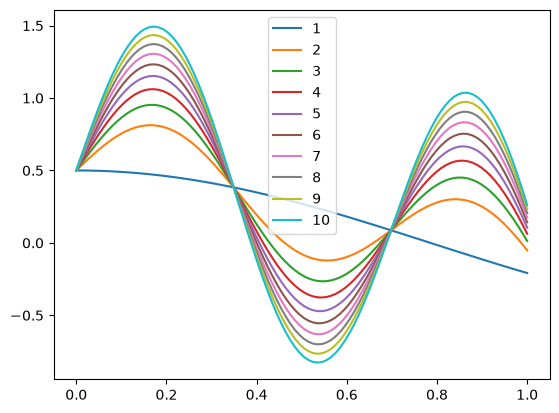

In [10]:
f_samples_labeled_df.plot(legend=True)


Question 6

In [11]:
t = np.linspace(0, 1, 100)

In [12]:
from scipy.interpolate import RegularGridInterpolator

# Convert the DataFrame to a 2D NumPy array with shape (len(t), len(a_values))
f_values_matrix = f_samples_labeled_df.values  # Shape: (100, 10) in this example

# Create an interpolator across `a` and `t`
interpolator = RegularGridInterpolator((t, a_values), f_values_matrix, method="linear", bounds_error=False, fill_value=None)

# Define a function that interpolates over a new `a` value
def interpolate_f_over_a(new_a):
    # Create a mesh of (time, new_a) points
    query_points = np.array([(time, new_a) for time in t])

    # Interpolate at all time points for the given new `a`
    return interpolator(query_points)

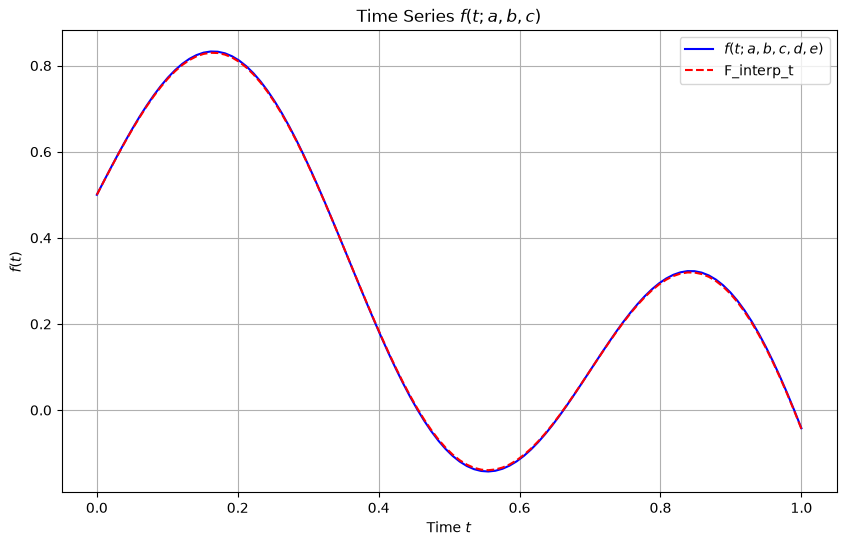

In [13]:
ap = 0.125
# Plot the function
plt.figure(figsize=(10, 6))
plt.plot(t, f(t, ap, b, c), label=r'$f(t; a, b, c, d, e)$', color='blue')
plt.plot(t, interpolate_f_over_a(ap), label=r'F_interp_t', color='red',ls='--')
plt.xlabel('Time $t$')
plt.ylabel(r'$f(t)$')
plt.title(r'Time Series $f(t; a, b, c)$')
plt.legend()
plt.grid(True)
plt.show()

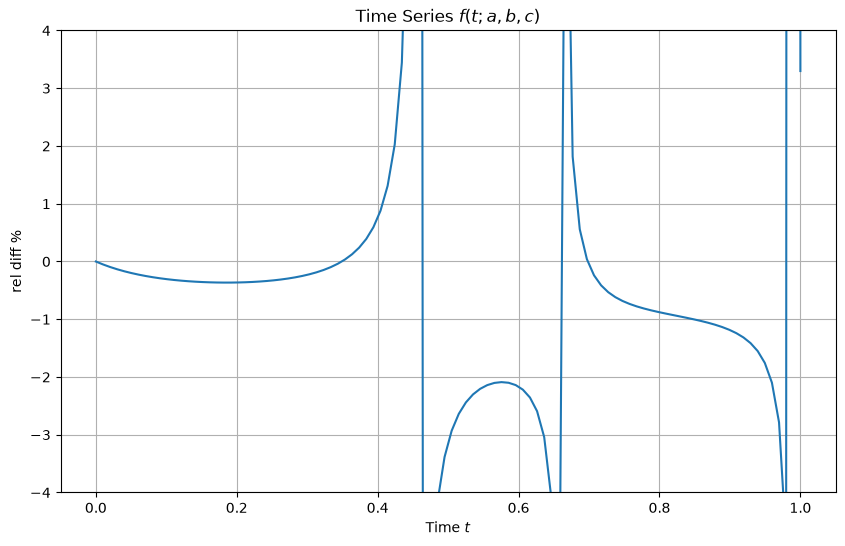

In [14]:
# Plot the function
plt.figure(figsize=(10, 6))
r = 100*(interpolate_f_over_a(ap)/f(t, ap, b, c) - 1 )
plt.plot(t,r)
plt.xlabel('Time $t$')
plt.ylabel(r'rel diff %')
plt.title(r'Time Series $f(t; a, b, c)$')
plt.grid(True)
plt.ylim(-4.,4.)
plt.show()

Question 7

In [ ]:
from ipywidgets import interact, FloatSlider
import ipywidgets as widgets

# Define the slider function to update the plot
def plot_interpolated_relative_difference(ap):
    # Calculate the relative difference
    r = 100 * (interpolate_f_over_a(ap) / f(t, ap, b, c) - 1.)

    # Plot the relative difference
    plt.figure(figsize=(10, 6))
    plt.plot(t, r)
    plt.xlabel('Time $t$')
    plt.ylabel(r'Relative Difference %')
    plt.title(r'Time Series $f(t; a, b, c)$')
    plt.ylim(-10,10)
    plt.grid(True)
    plt.show()

# Define the slider for `ap`
ap_slider = FloatSlider(value=0.145, min=0., max=1.0, step=0.001, description='ap')

# Use `interact` to create the interactive plot
interact(plot_interpolated_relative_difference, ap=ap_slider)

interactive(children=(FloatSlider(value=0.145, description='ap', max=1.0, step=0.001), Output()), _dom_classes…

<function __main__.plot_interpolated_relative_difference(ap)>